In [9]:
'''
本次作業主要練習 Python 機器學習（Machine Learning），包含資料集分割、分類模型訓練與模型評估。

請載入 sklearn.datasets 中的 Wine 葡萄酒資料集（load_wine()），並完成以下功能：

將資料集分割為訓練集與測試集。

訓練一個分類模型，例如 Random Forest 或 Logistic Regression。

計算並顯示模型在測試集上的準確率（Accuracy）。

繪製混淆矩陣（Confusion Matrix），評估模型的分類表現。

Wine 資料集包含 178 筆資料、13 個特徵，分類目標為 3 種不同的葡萄酒品種。
'''
import sklearn
import pandas as pd
import numpy as np
from sklearn import datasets
from sklearn.ensemble import RandomForestClassifier

wine = datasets.load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(df, wine.target, test_size=0.2, random_state=42)
model = RandomForestClassifier().fit(x_train, y_train)
print(model.score(x_test, y_test))
from sklearn.metrics import confusion_matrix
y_pred = model.predict(x_test)
print(confusion_matrix(y_test, y_pred))


#resources:
#https://realpython.com/train-test-split-python-data/
#https://www.geeksforgeeks.org/machine-learning/random-forest-algorithm-in-machine-learning/

1.0
[[14  0  0]
 [ 0 14  0]
 [ 0  0  8]]


Test accuracy: 1.0000


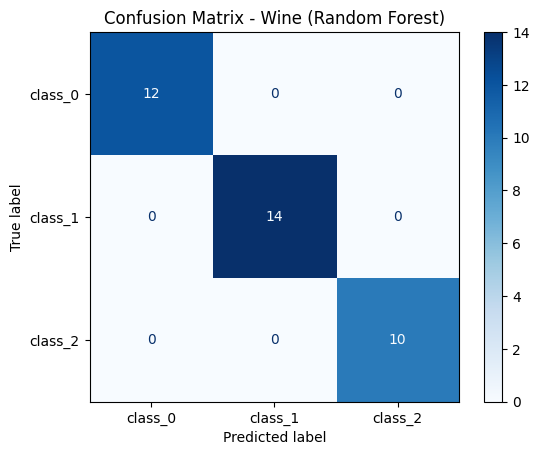

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Load the dataset
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train a classification model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Evaluate accuracy on the test set
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.4f}")

# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=wine.target_names)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Wine (Random Forest)")
plt.show()